In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Librerías cargadas correctamente")
print(f"  pandas  : {pd.__version__}")
print(f"  numpy   : {np.__version__}")
print(f"  yfinance: {yf.__version__}")

Librerías cargadas correctamente
  pandas  : 2.2.3
  numpy   : 1.26.4
  yfinance: 1.2.0


In [2]:
# Subconjunto de 50 acciones del S&P 500 diversificado por sectores
TICKERS = {
    "Tecnología":            ["AAPL", "MSFT", "NVDA", "GOOGL", "META", "AVGO", "AMD", "ORCL", "INTC", "QCOM"],
    "Salud":                 ["JNJ", "UNH", "LLY", "ABBV", "MRK", "TMO", "ABT", "PFE", "MDT", "BMY"],
    "Financiero":            ["JPM", "BAC", "WFC", "GS", "MS", "BLK", "AXP", "C", "USB", "PNC"],
    "Consumo discrecional":  ["AMZN", "TSLA", "HD", "MCD", "NKE", "SBUX", "TGT", "LOW", "F", "GM"],
    "Energía":               ["XOM", "CVX", "COP", "SLB", "EOG"],
    "Industrial":            ["CAT", "BA", "HON", "GE", "LMT"],
}

# Lista plana de todos los tickers
ALL_TICKERS = [t for sector in TICKERS.values() for t in sector]

print(f"Total de acciones: {len(ALL_TICKERS)}")
for sector, tickers in TICKERS.items():
    print(f"  {sector:<25}: {len(tickers)} acciones → {', '.join(tickers)}")

Total de acciones: 50
  Tecnología               : 10 acciones → AAPL, MSFT, NVDA, GOOGL, META, AVGO, AMD, ORCL, INTC, QCOM
  Salud                    : 10 acciones → JNJ, UNH, LLY, ABBV, MRK, TMO, ABT, PFE, MDT, BMY
  Financiero               : 10 acciones → JPM, BAC, WFC, GS, MS, BLK, AXP, C, USB, PNC
  Consumo discrecional     : 10 acciones → AMZN, TSLA, HD, MCD, NKE, SBUX, TGT, LOW, F, GM
  Energía                  : 5 acciones → XOM, CVX, COP, SLB, EOG
  Industrial               : 5 acciones → CAT, BA, HON, GE, LMT


In [3]:
# Descarga de datos históricos (5 años)
FECHA_INICIO = "2019-01-01"
FECHA_FIN    = "2024-12-31"

print(f"Descargando datos desde {FECHA_INICIO} hasta {FECHA_FIN}...")


datos = {}
errores = []

for sector, tickers in TICKERS.items():
    for ticker in tickers:
        try:
            df = yf.download(ticker, start=FECHA_INICIO, end=FECHA_FIN, 
                           progress=False, auto_adjust=True)
            if df.empty:
                errores.append(ticker)
            else:
                datos[ticker] = df
        except Exception as e:
            errores.append(ticker)

print(f" Descargados correctamente : {len(datos)} tickers")
if errores:
    print(f"  Con errores              : {errores}")
else:
    print(f"  Con errores              : ninguno")

print(f"\nEjemplo — AAPL, últimas 3 filas:")
print(datos["AAPL"].tail(3))

Descargando datos desde 2019-01-01 hasta 2024-12-31...
 Descargados correctamente : 50 tickers
  Con errores              : ninguno

Ejemplo — AAPL, últimas 3 filas:
Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2024-12-26  257.375580  258.448740  255.994420  256.550862  27237100
2024-12-27  253.967392  257.057664  251.453455  256.193162  42355300
2024-12-30  250.598907  251.890657  249.158116  250.628716  35557500


In [4]:
# Exploración básica del dataset
resumen = []

for ticker, df in datos.items():
    close = df["Close"].squeeze()  # Aplanamos de una vez para todo
    resumen.append({
        "ticker":        ticker,
        "desde":         df.index[0].date(),
        "hasta":         df.index[-1].date(),
        "sesiones":      len(df),
        "precio_actual": round(float(close.iloc[-1]), 2),
        "nulos":         int(close.isna().sum())
    })

df_resumen = pd.DataFrame(resumen)

print(f"Sesiones totales por ticker:")
print(f"  Mínimo : {df_resumen['sesiones'].min()} sesiones ({df_resumen.loc[df_resumen['sesiones'].idxmin(), 'ticker']})")
print(f"  Máximo : {df_resumen['sesiones'].max()} sesiones ({df_resumen.loc[df_resumen['sesiones'].idxmax(), 'ticker']})")
print(f"  Media  : {df_resumen['sesiones'].mean():.0f} sesiones")
print(f"  Nulos  : {df_resumen['nulos'].sum()} valores nulos en total")

print(f"\nPrecios de cierre a 30/12/2024:")
print(df_resumen[["ticker","desde","hasta","sesiones","precio_actual"]].to_string(index=False))

Sesiones totales por ticker:
  Mínimo : 1509 sesiones (AAPL)
  Máximo : 1509 sesiones (AAPL)
  Media  : 1509 sesiones
  Nulos  : 0 valores nulos en total

Precios de cierre a 30/12/2024:
ticker      desde      hasta  sesiones  precio_actual
  AAPL 2019-01-02 2024-12-30      1509         250.60
  MSFT 2019-01-02 2024-12-30      1509         419.85
  NVDA 2019-01-02 2024-12-30      1509         137.28
 GOOGL 2019-01-02 2024-12-30      1509         190.25
  META 2019-01-02 2024-12-30      1509         588.33
  AVGO 2019-01-02 2024-12-30      1509         232.61
   AMD 2019-01-02 2024-12-30      1509         122.44
  ORCL 2019-01-02 2024-12-30      1509         164.26
  INTC 2019-01-02 2024-12-30      1509          19.82
  QCOM 2019-01-02 2024-12-30      1509         149.68
   JNJ 2019-01-02 2024-12-30      1509         137.56
   UNH 2019-01-02 2024-12-30      1509         488.98
   LLY 2019-01-02 2024-12-30      1509         765.51
  ABBV 2019-01-02 2024-12-30      1509         167.50
   

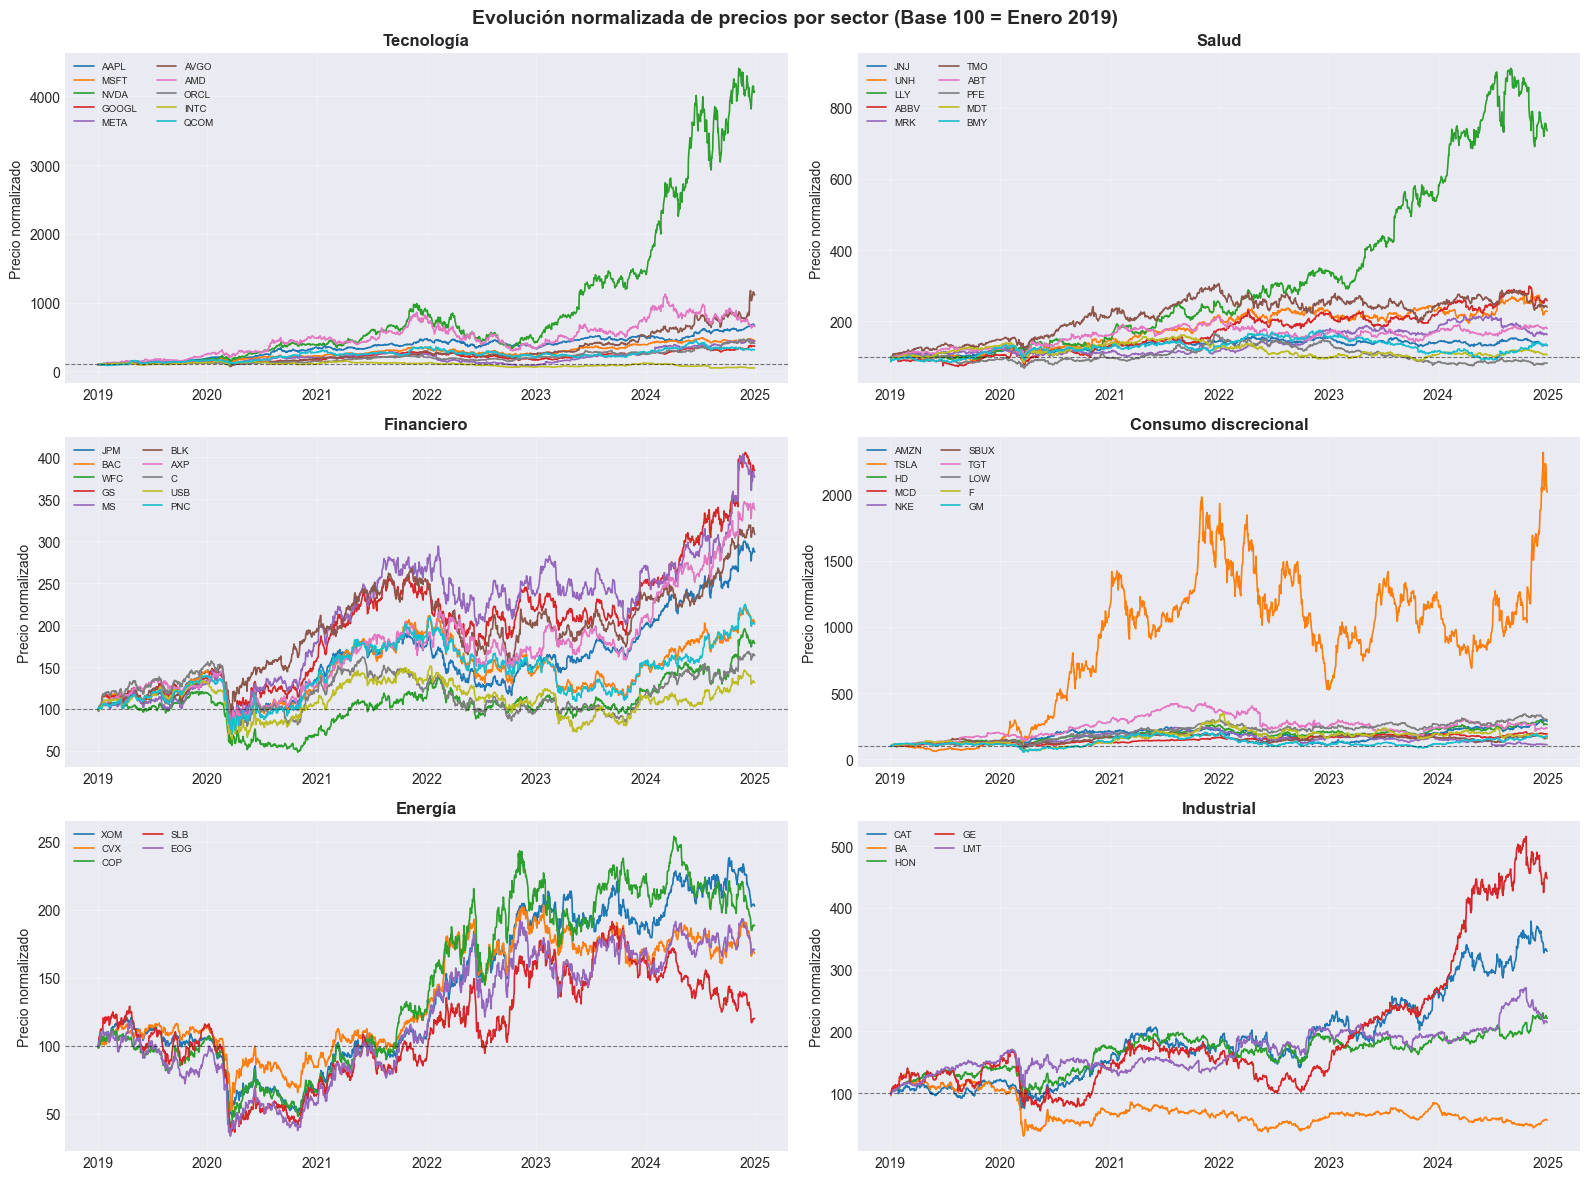

Gráfico guardado en results/


In [5]:
# Evolución normalizada de precios por sector (base 100 = enero 2019)
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Evolución normalizada de precios por sector (Base 100 = Enero 2019)", 
             fontsize=14, fontweight="bold")

axes = axes.flatten()
colores = plt.cm.tab10.colors

for idx, (sector, tickers) in enumerate(TICKERS.items()):
    ax = axes[idx]
    for i, ticker in enumerate(tickers):
        close = datos[ticker]["Close"].squeeze()
        normalizado = (close / close.iloc[0]) * 100
        ax.plot(normalizado.index, normalizado.values, 
                label=ticker, color=colores[i % len(colores)], linewidth=1.2)
    
    ax.set_title(sector, fontweight="bold")
    ax.set_ylabel("Precio normalizado")
    ax.axhline(100, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/01_evolucion_por_sector.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfico guardado en results/")

In [6]:
# Cálculo de retornos diarios
retornos = pd.DataFrame()

for ticker in ALL_TICKERS:
    close = datos[ticker]["Close"].squeeze()
    retornos[ticker] = close.pct_change()

retornos = retornos.dropna()

print(f"Matriz de retornos: {retornos.shape[0]} días x {retornos.shape[1]} acciones")
print(f"\nEstadísticas básicas (primeras 5 acciones):")
print(retornos[["AAPL","MSFT","NVDA","TSLA","JPM"]].describe().round(4))

Matriz de retornos: 1508 días x 50 acciones

Estadísticas básicas (primeras 5 acciones):
            AAPL       MSFT       NVDA       TSLA        JPM
count  1508.0000  1508.0000  1508.0000  1508.0000  1508.0000
mean      0.0014     0.0012     0.0030     0.0028     0.0009
std       0.0194     0.0183     0.0327     0.0406     0.0193
min      -0.1286    -0.1474    -0.1845    -0.2106    -0.1496
25%      -0.0079    -0.0075    -0.0154    -0.0180    -0.0078
50%       0.0015     0.0012     0.0032     0.0020     0.0009
75%       0.0119     0.0107     0.0205     0.0222     0.0094
max       0.1198     0.1422     0.2437     0.2192     0.1801


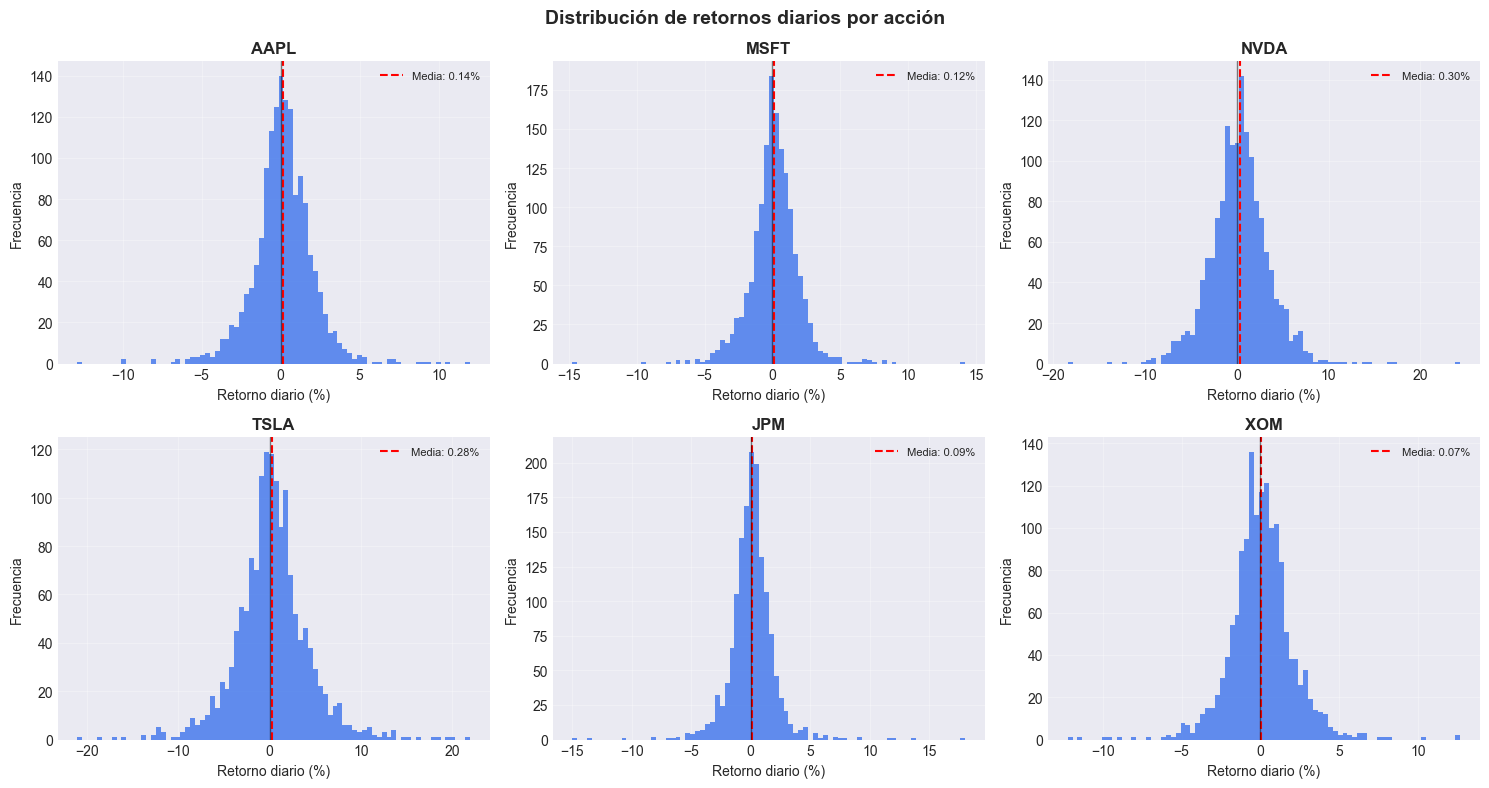

Gráfico guardado en results/


In [7]:
# Distribución de retornos diarios de acciones representativas
acciones_ejemplo = ["AAPL", "MSFT", "NVDA", "TSLA", "JPM", "XOM"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Distribución de retornos diarios por acción", 
             fontsize=14, fontweight="bold")

axes = axes.flatten()

for idx, ticker in enumerate(acciones_ejemplo):
    ax = axes[idx]
    retornos_ticker = retornos[ticker] * 100  # Pasamos a porcentaje
    
    ax.hist(retornos_ticker, bins=80, color="#2563eb", alpha=0.7, edgecolor="none")
    ax.axvline(retornos_ticker.mean(), color="red", linewidth=1.5, 
               linestyle="--", label=f"Media: {retornos_ticker.mean():.2f}%")
    ax.axvline(0, color="black", linewidth=1, alpha=0.5)
    
    ax.set_title(ticker, fontweight="bold")
    ax.set_xlabel("Retorno diario (%)")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/02_distribucion_retornos.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfico guardado en results/")

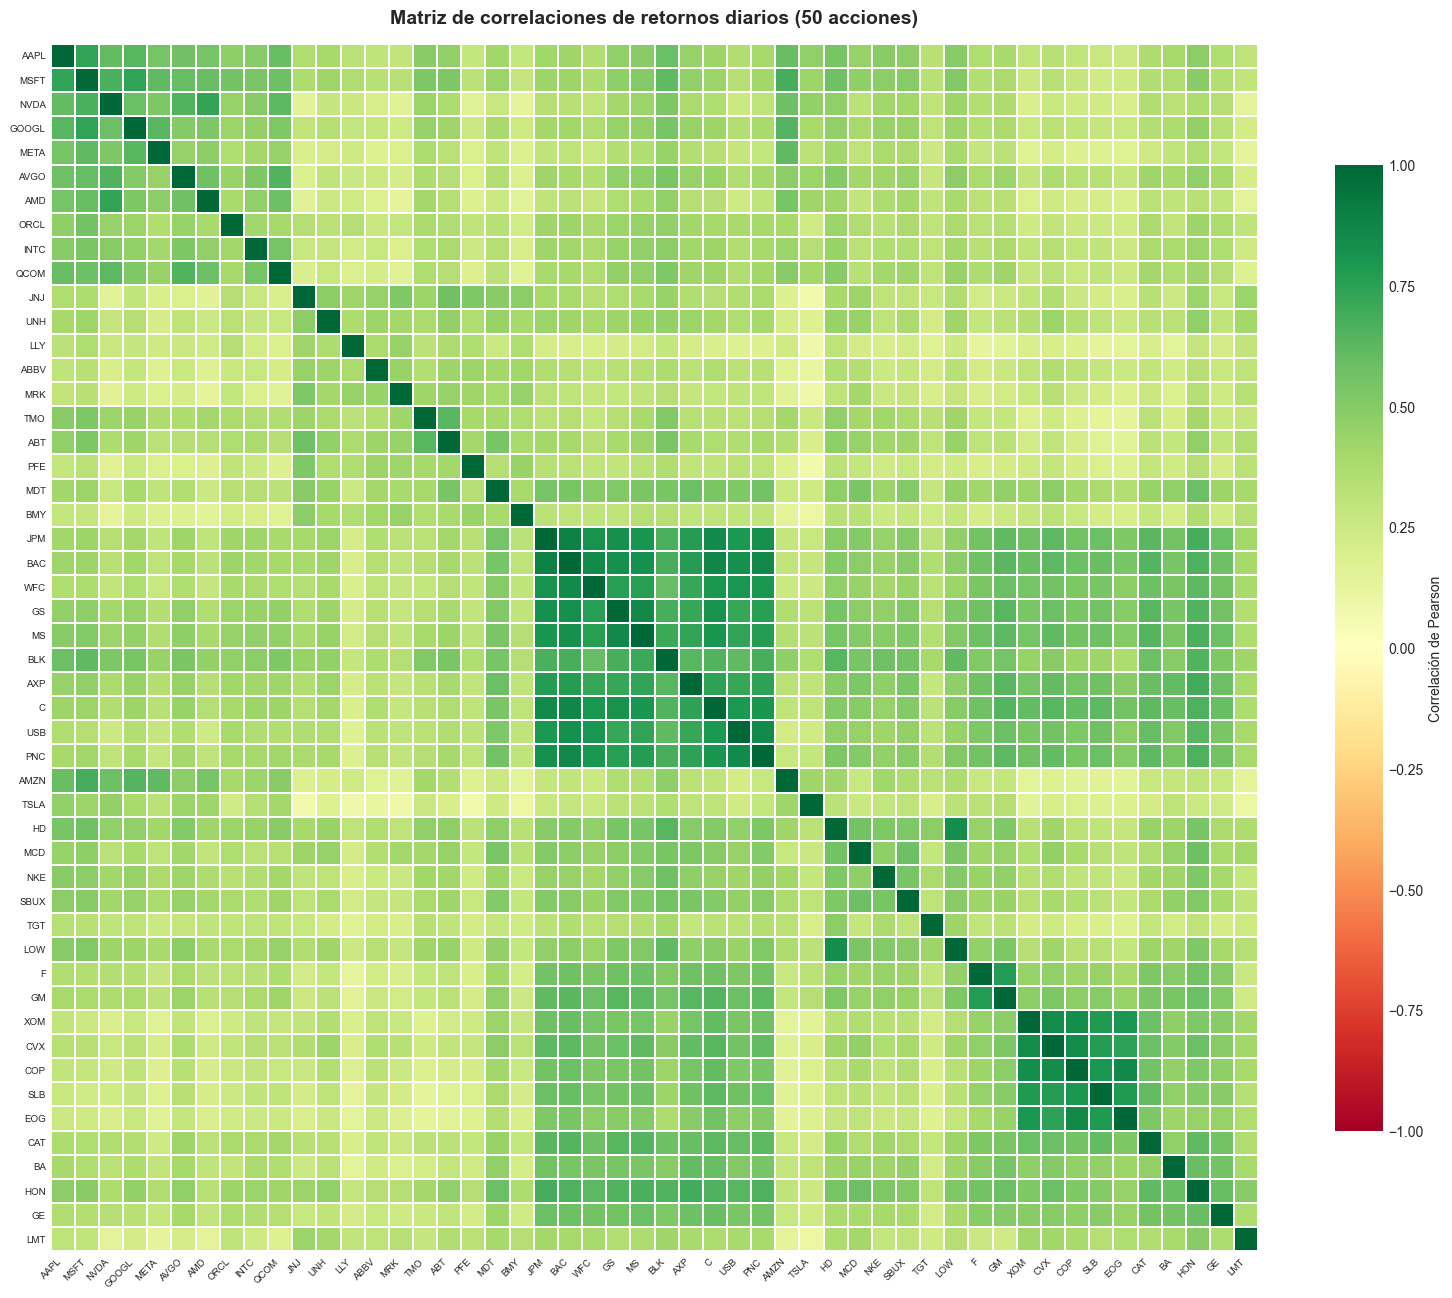

Gráfico guardado en results/


In [8]:
# Matriz de correlaciones entre los 50 activos
correlaciones = retornos.corr()

fig, ax = plt.subplots(figsize=(16, 13))

mascara = np.zeros_like(correlaciones, dtype=bool)  # Sin máscara

sns.heatmap(
    correlaciones,
    ax=ax,
    cmap="RdYlGn",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.3,
    annot=False,
    cbar_kws={"shrink": 0.8, "label": "Correlación de Pearson"}
)

ax.set_title("Matriz de correlaciones de retornos diarios (50 acciones)", 
             fontsize=14, fontweight="bold", pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)

plt.tight_layout()
plt.savefig("../results/03_correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfico guardado en results/")

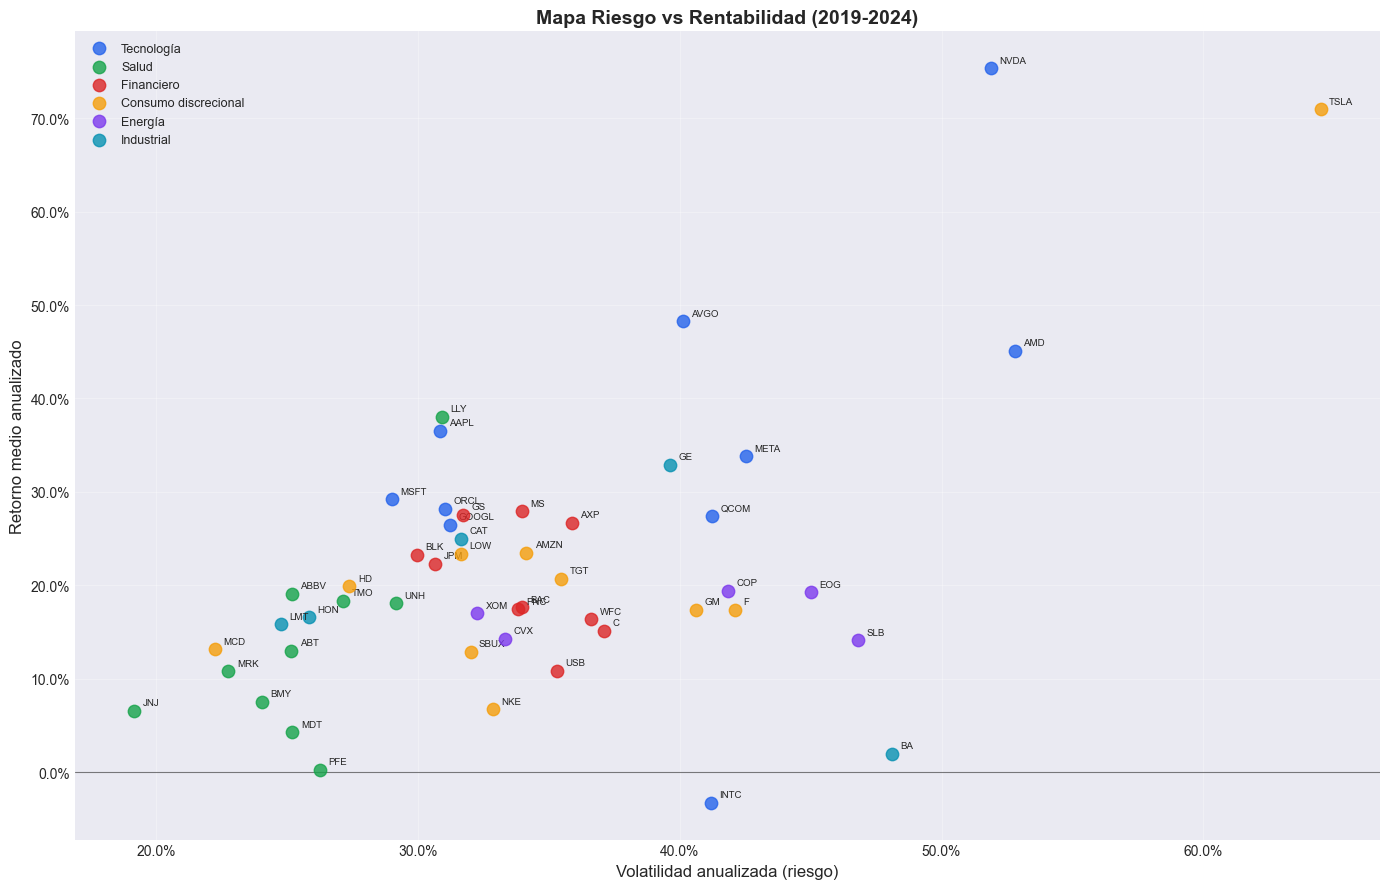

Gráfico guardado en results/


In [9]:
# Gráfico riesgo vs rentabilidad de las 50 acciones
retorno_anual = retornos.mean() * 252        # 252 días de trading al año
volatilidad_anual = retornos.std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(14, 9))

# Colores por sector
colores_sector = {
    "Tecnología":           "#2563eb",
    "Salud":                "#16a34a",
    "Financiero":           "#dc2626",
    "Consumo discrecional": "#f59e0b",
    "Energía":              "#7c3aed",
    "Industrial":           "#0891b2",
}

for sector, tickers in TICKERS.items():
    x = [volatilidad_anual[t] for t in tickers]
    y = [retorno_anual[t] for t in tickers]
    ax.scatter(x, y, label=sector, color=colores_sector[sector], 
               s=80, alpha=0.8, zorder=3)
    for t in tickers:
        ax.annotate(t, 
                    (volatilidad_anual[t], retorno_anual[t]),
                    textcoords="offset points", xytext=(6, 4), fontsize=7)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_xlabel("Volatilidad anualizada (riesgo)", fontsize=12)
ax.set_ylabel("Retorno medio anualizado", fontsize=12)
ax.set_title("Mapa Riesgo vs Rentabilidad (2019-2024)", 
             fontsize=14, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x*100:.1f}%"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x*100:.1f}%"))

plt.tight_layout()
plt.savefig("../results/04_riesgo_rentabilidad.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfico guardado en results/")

In [ ]:
# NOTA: Esta celda intenta actualizar el dataset FNSPID con noticias
# posteriores al 9 de enero de 2024. El dataset no ha sido actualizado
# desde esa fecha, por lo que esta celda no añade noticias nuevas y
# puede tardar varias horas en completarse sin resultado.
# El dataset completo (159.997 noticias) ya está guardado en:
# ../datos/fnspid_50tickers.parquet
# Si no hay actualizaciones disponibles, saltar esta celda.


import sys
print("Dataset FNSPID ya actualizado. Saltando descarga.")
sys.exit(0)  # Comentar esta línea si se quiere forzar la actualización

#Añadir key de huggin face
'''
import os
os.environ["HF_TOKEN"] = "*******" 

from datasets import load_dataset
import pandas as pd

# Tickers principales + tickers historicos mapeados a su ticker actual
TICKERS_ACTUALES = [
    "AAPL", "MSFT", "NVDA", "GOOGL", "META", "AVGO", "AMD", "ORCL", "INTC", "QCOM",
    "JNJ", "UNH", "LLY", "ABBV", "MRK", "TMO", "ABT", "PFE", "MDT", "BMY",
    "JPM", "BAC", "WFC", "GS", "MS", "BLK", "AXP", "C", "USB", "PNC",
    "AMZN", "TSLA", "HD", "MCD", "NKE", "SBUX", "TGT", "LOW", "F", "GM",
    "XOM", "CVX", "COP", "SLB", "EOG", "CAT", "BA", "HON", "GE", "LMT",
]

# Mapa de tickers historicos al ticker actual
# Si el dataset tiene "FB" lo guardamos como "META", etc.
MAPA_HISTORICO = {
    "FB":   "META",   # Facebook → Meta (oct 2021)
    "GOOG": "GOOGL",  # clase C → clase A
}

# Todos los tickers a buscar en el dataset (actuales + historicos)
TICKERS_BUSCAR = TICKERS_ACTUALES + list(MAPA_HISTORICO.keys())

RUTA_PARQUET = "../datos/fnspid_50tickers.parquet"
RUTA_CSV     = "../datos/fnspid_50tickers.csv"
GUARDAR_CADA = 10_000

# Cargamos lo existente y sacamos la ultima fecha
if os.path.exists(RUTA_PARQUET):
    df_existente = pd.read_parquet(RUTA_PARQUET)
    df_existente["Date"] = pd.to_datetime(df_existente["Date"])
    ultima_fecha = df_existente["Date"].max()
    print(f"Noticias existentes : {len(df_existente)}")
    print(f"Ultima fecha guardada: {ultima_fecha.date()}")
    print(f"Buscando noticias posteriores a {ultima_fecha.date()}...")
else:
    df_existente = pd.DataFrame(columns=["Date", "Title", "Ticker"])
    ultima_fecha = pd.Timestamp("2018-12-31")
    print("Empezando desde cero")

print("\nConectando con FNSPID en streaming...")
ds = load_dataset("Zihan1004/FNSPID",
                  split="train",
                  streaming=True,
                  token=os.environ["HF_TOKEN"])

filas_nuevas = []
contador     = 0
encontradas  = 0
saltadas     = 0

for fila in ds:
    contador += 1

    try:
        ticker_raw = (fila.get("Stock_symbol") or
                      fila.get("stock_symbol") or
                      fila.get("ticker", ""))

        if ticker_raw and ticker_raw in TICKERS_BUSCAR:
            fecha = pd.to_datetime(fila.get("Date") or fila.get("date"), utc=True)
            fecha = fecha.replace(tzinfo=None)

            # Solo fechas nuevas y dentro del rango
            if fecha > ultima_fecha and 2019 <= fecha.year <= 2024:
                titulo = (fila.get("Article_title") or
                          fila.get("title") or
                          fila.get("headline", ""))

                if titulo:
                    # Mapeamos ticker historico al actual
                    ticker_final = MAPA_HISTORICO.get(ticker_raw, ticker_raw)

                    filas_nuevas.append({
                        "Date":   fecha.strftime("%Y-%m-%d"),
                        "Title":  titulo,
                        "Ticker": ticker_final,
                    })
                    encontradas += 1

                    # Guardado progresivo
                    if encontradas % GUARDAR_CADA == 0:
                        df_temp = pd.concat([
                            df_existente,
                            pd.DataFrame(filas_nuevas)
                        ], ignore_index=True).drop_duplicates()
                        df_temp.to_parquet(RUTA_PARQUET, index=False)
                        print(f"  Guardado parcial: {len(df_temp)} noticias totales")
            else:
                saltadas += 1

    except Exception:
        pass

    if contador % 200_000 == 0:
        print(f"  Procesadas {contador:,} filas — "
              f"{encontradas:,} nuevas — "
              f"{saltadas:,} saltadas")

# Guardado final
if filas_nuevas:
    df_final = pd.concat([
        df_existente,
        pd.DataFrame(filas_nuevas)
    ], ignore_index=True).drop_duplicates()
    df_final["Date"] = pd.to_datetime(df_final["Date"])
    df_final = df_final.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    df_final.to_parquet(RUTA_PARQUET, index=False)
    df_final.to_csv(RUTA_CSV, index=False)

    print(f"\n{'='*50}")
    print(f"DESCARGA COMPLETADA")
    print(f"Noticias nuevas   : {len(filas_nuevas)}")
    print(f"Total noticias    : {len(df_final)}")
    print(f"Rango fechas      : {df_final['Date'].min().date()} -> {df_final['Date'].max().date()}")
    print(f"\nNoticias por ticker:")
    print(df_final["Ticker"].value_counts().to_string())
    print(f"\nTickers sin noticias:")
    sin = [t for t in TICKERS_ACTUALES if t not in df_final["Ticker"].values]
    print(sin if sin else "Ninguno")
else:
    print("\nNo se encontraron noticias nuevas")
    print("El dataset puede estar completo o el token ha expirado")

'''

Dataset FNSPID ya actualizado. Saltando descarga.


SystemExit: 0

C:\Users\Ferpo\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\interactiveshell.py:3585: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [13]:
import pandas as pd

df = pd.read_parquet("../datos/fnspid_50tickers.parquet")
df["Date"] = pd.to_datetime(df["Date"])

print(f"Total noticias: {len(df)}")
print(f"Rango: {df['Date'].min().date()} → {df['Date'].max().date()}")

# Verificamos si hay FB o GOOG ya mapeados a META y GOOGL
print(f"\nNoticias META  : {(df['Ticker'] == 'META').sum()}")
print(f"Noticias GOOGL : {(df['Ticker'] == 'GOOGL').sum()}")
print(f"Noticias HON   : {(df['Ticker'] == 'HON').sum()}")

# Tickers sin noticias
TICKERS = [
    "AAPL","MSFT","NVDA","GOOGL","META","AVGO","AMD","ORCL","INTC","QCOM",
    "JNJ","UNH","LLY","ABBV","MRK","TMO","ABT","PFE","MDT","BMY",
    "JPM","BAC","WFC","GS","MS","BLK","AXP","C","USB","PNC",
    "AMZN","TSLA","HD","MCD","NKE","SBUX","TGT","LOW","F","GM",
    "XOM","CVX","COP","SLB","EOG","CAT","BA","HON","GE","LMT"
]
sin_noticias = [t for t in TICKERS if t not in df["Ticker"].values]
print(f"\nTickers sin noticias: {sin_noticias}")

Total noticias: 159997
Rango: 2019-01-01 → 2024-01-09

Noticias META  : 0
Noticias GOOGL : 1453
Noticias HON   : 0

Tickers sin noticias: ['META', 'HON']
